# Project 1: natural language inference with SNLI

This notebook follows [PROJECT1_PLAN.md](PROJECT1_PLAN.md).

**Current status: Steps 1–6 are complete and verified. Step 7 is next.**
Workspace setup, inspection, grouped folds, features, classifiers, and the SNLI
pilot are implemented below. Steps 3–4 preserve the full-pool reference design;
section 6 records the separate pilot-selected comparison pool and frozen
configuration. Reported CV comparisons and final test scoring remain pending
in sections 7–11.

Our planned systems compare three fixed representations (token indicators,
unigram counts, and unigram-plus-bigram counts) and three classifiers
(log-linear softmax regression and one- and two-hidden-layer ReLU MLPs).
[COURSE_METHODS.md](COURSE_METHODS.md) maps these choices to the lectures and T1.

Run All executes setup, the data audit, saved-fold checks, and one fold of
feature preparation, plus small synthetic classifier/reload checks.
Section 6 loads the saved measured pilot; Run All does not retrain it.
The first feature run fits BPE/builds sparse matrices;
later runs verify and reload their cache. The first data load needs internet;
later runs reuse the local Hugging Face cache.

## 1. Workspace and reproducibility

### 1.1 Locate the repository

Select the repository's `.venv/bin/python` as the notebook kernel. This cell
finds the repository from either the root directory or `part1`, so local package
imports use the same code as the command-line setup.

In [1]:
from pathlib import Path
import sys

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "part1" / "project.ipynb").is_file():
        REPO_ROOT = candidate
        break
else:
    raise FileNotFoundError("Open this notebook from the repository root or part1.")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print("Repository:", REPO_ROOT)
print("Kernel Python:", sys.executable)
print("Environment prefix:", sys.prefix)

Repository: /home/borisv/nlp1-student-gp57
Kernel Python: /home/borisv/nlp1-student-gp57/.venv/bin/python
Environment prefix: /home/borisv/nlp1-student-gp57/.venv


### 1.2 Load the shared configuration and prepare local outputs

The notebook and `python -m part1.project_setup` both call
[project_setup.py](project_setup.py), reading
[configs/snli_project1.json](configs/snli_project1.json).

The dataset revision is pinned, while model hyperparameters remain provisional
until the pilot. `num_epochs` is deliberately unset. Setup seeds Python, NumPy,
and PyTorch and writes a manifest without loading dataset rows.

This is the reference/pilot configuration. Section 6 records the separate
[post-pilot frozen configuration](configs/snli_project1_frozen.json), including
the selected epoch count and comparison data budget. Step 7 must use that file.

In [2]:
import pandas as pd
from IPython.display import display
from part1.project_setup import prepare_workspace

workspace = prepare_workspace()
config = workspace["config"]
manifest = workspace["manifest"]
paths = workspace["paths"]

settings = [
    ("Configuration status", config["status"]),
    ("Dataset", config["dataset"]["repo_id"]),
    ("Dataset revision", config["dataset"]["revision"]),
    ("Device", config["device"]),
    ("Model seed", config["seeds"]["model"]),
    ("Sampling seed", config["seeds"]["sampling"]),
    ("CV split seeds", str(config["seeds"]["cv_splits"])),
    ("CV folds", config["cross_validation"]["num_folds"]),
    ("Representations", ", ".join(config["representations"])),
    ("Classifiers", ", ".join(config["classifiers"])),
    ("Primary metric", config["evaluation"]["primary_metric"]),
    ("ROPE half-width", config["evaluation"]["rope_half_width"]),
]
display(pd.DataFrame(settings, columns=["Setting", "Value"]))

,Setting,Value
0,Configuration status,provisional_before_pilot
1,Dataset,stanfordnlp/snli
2,Dataset revision,cdb5c3d5eed6ead6e5a341c8e56e669bb666725b
3,Device,cpu
4,Model seed,0
5,Sampling seed,0
6,CV split seeds,"[0, 3, 5]"
7,CV folds,5
8,Representations,"indicators, unigram_counts, unigram_bigram_counts"
9,Classifiers,"logistic, mlp_one_hidden, mlp_two_hidden"


### 1.3 Record the actual environment

The course README uses Python 3.14; this workspace currently uses Python 3.12.3
and CPU PyTorch. We record the actual versions rather than claiming these
setups are identical. The tracked [environment.txt](environment.txt) is the
initial package snapshot; each execution also captures its own snapshot.

Git state matters: a commit identifies committed source, while a dirty working
tree means the manifest also describes uncommitted work. After reviewing and
committing changes, rerun setup to record that committed version.

In [3]:
print("Python version:", manifest["python"]["version"])
print("Configured device:", manifest["hardware"]["configured_device"])
print("Platform:", manifest["hardware"]["platform"])
print("Logical CPUs:", manifest["hardware"]["logical_cpu_count"])
print("Git commit:", manifest["repository"]["commit"])
print("Working tree dirty:", manifest["repository"]["dirty"])
print("Config SHA-256:", manifest["config_sha256"])

core_packages = [
    "numpy", "scipy", "pandas", "matplotlib", "scikit-learn",
    "torch", "datasets", "tokenizers", "baycomp", "ipykernel",
]
display(pd.DataFrame(
    [(name, manifest["packages"][name]) for name in core_packages],
    columns=["Package", "Installed version"],
))

Python version: 3.12.3
Configured device: cpu
Platform: Linux-7.0.0-42-generic-x86_64-with-glibc2.39
Logical CPUs: 16
Git commit: c92d4a27d6ce0f58ecc8d96650663ba8ece2ec04
Working tree dirty: True
Config SHA-256: a44fe5e996b3716dad5e8f1ef88a12e4df6e7e2b1618c645b297d658a33b9a18


,Package,Installed version
0,numpy,2.5.4
1,scipy,1.18.1
2,pandas,3.1.1
3,matplotlib,3.11.2
4,scikit-learn,1.9.1
5,torch,2.15.0+cpu
6,datasets,5.1.0
7,tokenizers,0.23.3
8,baycomp,1.0.3
9,ipykernel,7.4.0


### 1.4 Inspect output locations

These directories are local and ignored by Git. The setup manifest, package
snapshot, data-audit figures, and saved folds are available. Predictions and
models will be added by later steps. Each training run will need its own provenance record; the setup
manifest is only the latest workspace record.

In [4]:
display(pd.DataFrame(
    [(name, str(path.relative_to(REPO_ROOT))) for name, path in paths.items()],
    columns=["Artifact group", "Repository-relative directory"],
))
print("Setup manifest:", manifest["artifacts"]["setup_manifest"])
print("Current package snapshot:", manifest["artifacts"]["environment"])
print("Dataset loaded during workspace setup:", manifest["dataset_loaded"])

,Artifact group,Repository-relative directory
0,output,part1/results/project1
1,data,part1/data
2,manifests,part1/results/project1/manifests
3,figures,part1/results/project1/figures
4,metrics,part1/results/project1/metrics
5,predictions,part1/results/project1/predictions
6,checkpoints,part1/results/project1/checkpoints
7,folds,part1/results/project1/folds
8,features,part1/results/project1/features


Setup manifest: /home/borisv/nlp1-student-gp57/part1/results/project1/manifests/setup.json
Current package snapshot: /home/borisv/nlp1-student-gp57/part1/results/project1/manifests/environment.txt
Dataset loaded during workspace setup: False


### 1.5 Why record seeds and versions?

A seed documents a particular pseudorandom sequence in a given software setup;
it does not remove experimental variation or prove that research replicates.
Later we will compare paired scores across several saved fold partitions and
record split seeds separately from model initialization seeds. Dedicated random
generators will also receive explicit seeds.

**Course connection:** HC2a Text Classification, physical PDF page 47; tutorial
1, Experiment. See [COURSE_METHODS.md](COURSE_METHODS.md) for the source index.

**Step 1 outcome:** shared configuration, environment/provenance records, and
output paths are ready. Dataset inspection is recorded in section 2.

## 2. Load, clean, and understand SNLI

### 2.1 Task: a conditional distribution over three labels

Let $x=(P,H)$ be a premise/hypothesis pair and $K=3$. A classifier's probabilistic
model prescribes $p_\theta(y\mid P,H)$, and its decision rule chooses
$\hat y=\arg\max_k p_\theta(k\mid P,H)$.

| ID | Label | Meaning relative to the premise |
| --- | --- | --- |
| 0 | entailment | The hypothesis follows from the premise |
| 1 | neutral | The premise does not establish the hypothesis or its negation |
| 2 | contradiction | The hypothesis conflicts with the premise |

For illustration only, a pmf $(0.6,0.3,0.1)$ over these labels would lead argmax
to choose entailment. These are illustrative probabilities, **not predictions
from an experiment**. The pmf contains more information than its winning label.

SNLI is an English natural-language-inference corpus built using caption
premises and crowdwritten hypotheses. This domain and collection procedure are
important limitations when interpreting future scores. Sources:
[dataset card](https://huggingface.co/datasets/stanfordnlp/snli),
[Bowman et al., 2015](https://aclanthology.org/D15-1075/), and HC2a PDF pages 8–9.

### 2.2 Load the pinned source and apply a documented cleaning policy

[snli_data.py](snli_data.py) verifies the label names in the dataset metadata,
retains the official splits, and filters rows with labels outside `{0,1,2}` or
missing/whitespace-only text. Exclusion reasons are counted once: invalid labels
first, then unusable text among remaining rows.

Original text, labels, order, and duplicate pairs are retained. Each row has an
`example_id` such as `train:24750`, plus `source_split` and `source_row`; the row
number is the original zero-based position, not a new index after filtering.
These metadata fields are for provenance, **not classifier inputs**.

The cleaned DatasetDict is saved locally for later folds/features. This step
only audits held-out split structure/counts; it does not score or select models
on the test set.

Hugging Face reuses its downloaded cache on subsequent runs. Cached data is
still the real dataset; an offline-cache message describes how it was accessed.
The output below shows split sizes and one loaded sentence pair. Progress bars
are disabled here so saved outputs do not depend on live Jupyter widgets.

In [5]:
from datasets import disable_progress_bars as disable_dataset_progress
from huggingface_hub.utils import disable_progress_bars as disable_hub_progress
from part1.snli_data import LABEL_NAMES, prepare_snli_report

# Keep saved outputs readable without a live progress-bar widget.
disable_dataset_progress()
disable_hub_progress()

snli_report = prepare_snli_report()
dataset = snli_report["cleaned"]
data_tables = snli_report["tables"]

print("Dataset revision:", snli_report["manifest"]["dataset"]["revision"])
print("Verified label mapping:", dict(enumerate(LABEL_NAMES)))
print("Prepared dataset:", snli_report["prepared_dir"])
display(dataset)
print("First loaded training example:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([dataset["train"][0]])[
        ["example_id", "premise", "hypothesis", "label"]
    ])

Dataset revision: cdb5c3d5eed6ead6e5a341c8e56e669bb666725b
Verified label mapping: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
Prepared dataset: /home/borisv/nlp1-student-gp57/part1/data/snli/cdb5c3d5eed6ead6e5a341c8e56e669bb666725b/cleaned-v1


DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'source_row', 'source_split', 'example_id'],
        num_rows: 549367
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label', 'source_row', 'source_split', 'example_id'],
        num_rows: 9842
    })
    test: Dataset({
        features: ['premise', 'hypothesis', 'label', 'source_row', 'source_split', 'example_id'],
        num_rows: 9824
    })
})

First loaded training example:


,example_id,premise,hypothesis,label
0,train:0,A person on a horse jumps over a broken down airplane.,A person is training his horse for a competition.,1


### 2.3 Split sizes, removals, and class balance

The cleaned dataset contains 549,367 training, 9,842 validation, and 9,824 test
examples. At this pinned revision, all 1,119 removals are invalid labels; no
missing/empty sentences were found. The tables below are computed from source
rows rather than entered as experimental results by hand.

In [6]:
size_columns = [
    "split", "raw_rows", "invalid_label_rows",
    "invalid_text_rows_after_label_filter", "clean_rows",
]
display(data_tables["split_summary"][size_columns])
class_table = data_tables["label_counts"].copy()
class_table["percentage"] = (100 * class_table["proportion"]).round(2)
display(class_table[["split", "label", "label_name", "count", "percentage"]])

,split,raw_rows,invalid_label_rows,invalid_text_rows_after_label_filter,clean_rows
0,train,550152,785,0,549367
1,validation,10000,158,0,9842
2,test,10000,176,0,9824


,split,label,label_name,count,percentage
0,train,0,entailment,183416,33.39
1,train,1,neutral,182764,33.27
2,train,2,contradiction,183187,33.35
3,validation,0,entailment,3329,33.82
4,validation,1,neutral,3235,32.87
5,validation,2,contradiction,3278,33.31
6,test,0,entailment,3368,34.28
7,test,1,neutral,3219,32.77
8,test,2,contradiction,3237,32.95


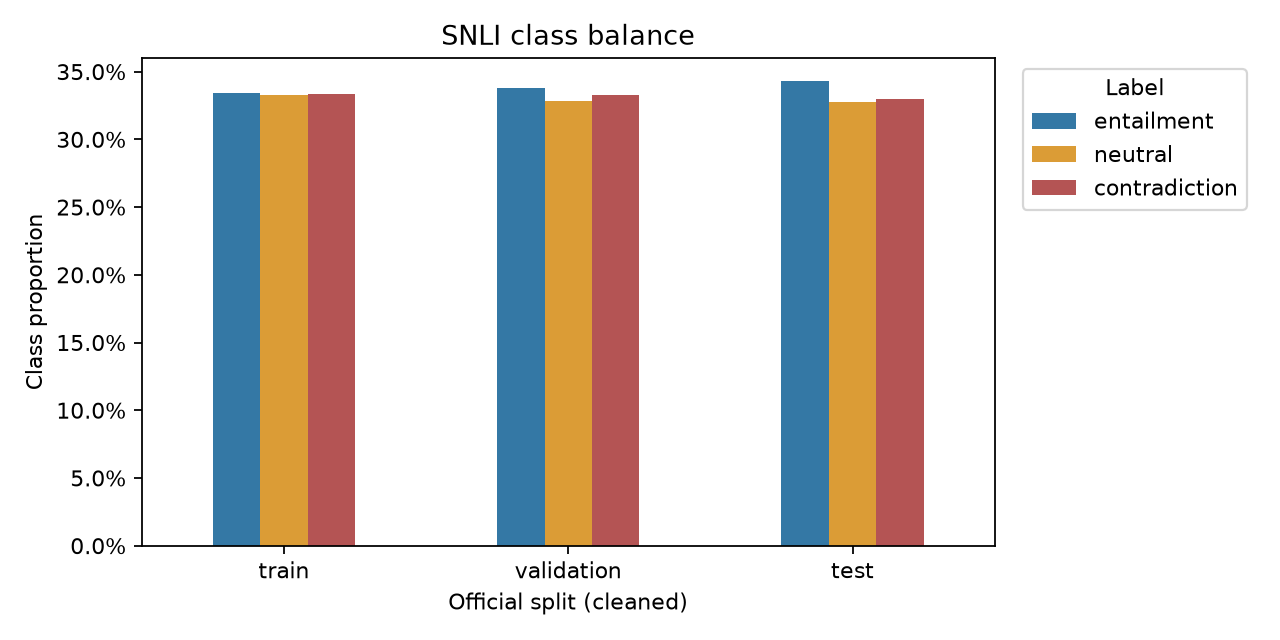

In [7]:
from IPython.display import Image

display(Image(filename=str(snli_report["figures"]["class_balance"])))

The training classes are almost balanced: entailment 33.39%, neutral 33.27%,
and contradiction 33.35%. This supports accuracy as a primary metric. We will
also report macro-F1/class metrics so the average cannot conceal class-specific
failures, and held-out NLL to evaluate predicted probabilities (HC2a page 46).

### 2.4 Sentence lengths depend on the segmentation procedure

These exploratory lengths count characters and whitespace-separated units using
Python's `str.split()`. They are **not BPE lengths** and do not train a tokenizer
on held-out data. Training premises average 12.85 whitespace units (median 12),
and hypotheses average 7.42 (median 7). This also motivates keeping the two
sentence roles explicit in the input representation.

,split,field,unit,min,mean,median,p95,max
0,train,premise,characters,7,66.27,60.0,121.0,402
1,train,premise,whitespace_tokens,2,12.85,12.0,23.0,78
2,train,hypothesis,characters,1,37.47,34.0,67.0,295
3,train,hypothesis,whitespace_tokens,1,7.42,7.0,13.0,56
4,validation,premise,characters,13,72.25,64.0,131.0,300
5,validation,premise,whitespace_tokens,2,13.94,12.0,25.0,50
6,validation,hypothesis,characters,6,37.90,35.0,68.0,232
7,validation,hypothesis,whitespace_tokens,2,7.51,7.0,13.0,48
8,test,premise,characters,9,71.94,64.0,130.0,265
9,test,premise,whitespace_tokens,2,13.91,13.0,25.0,54


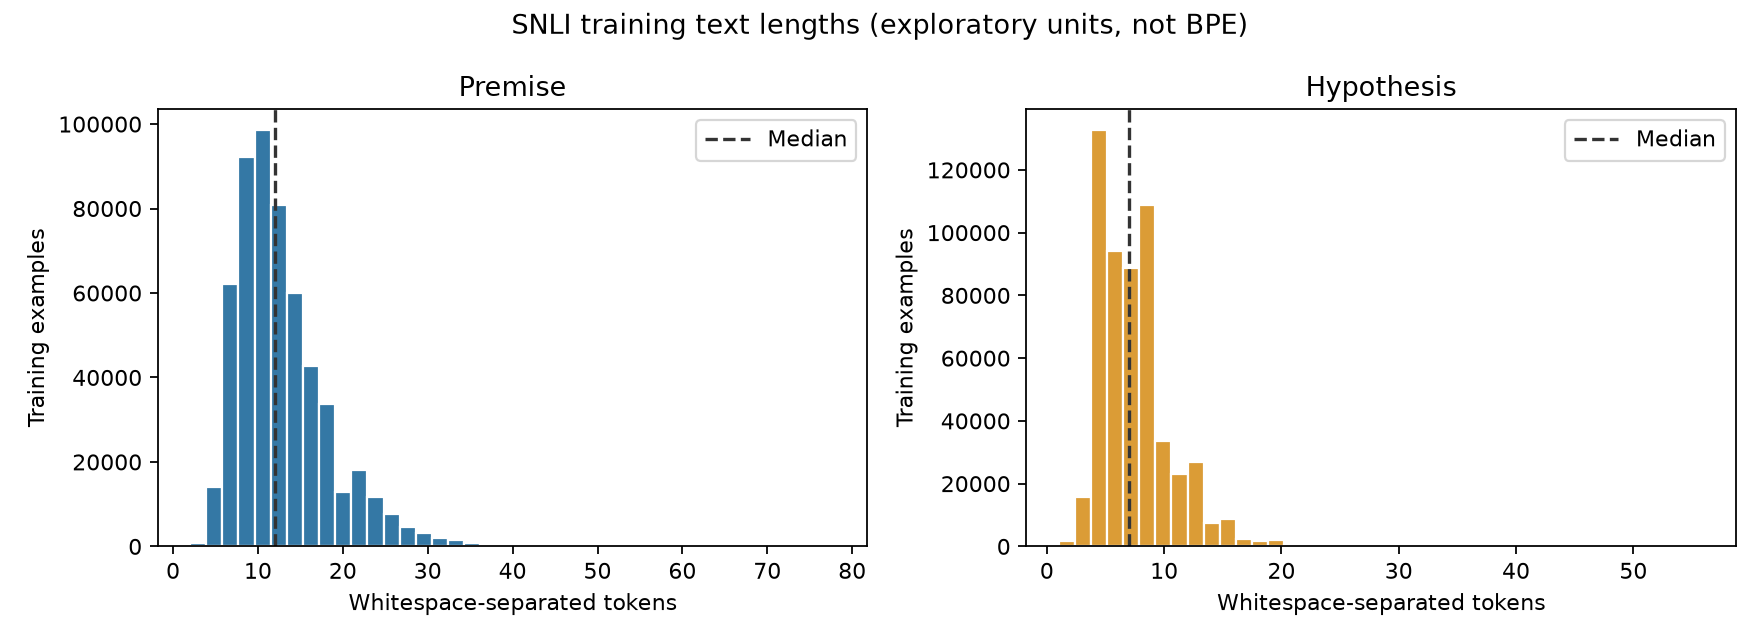

In [8]:
display(data_tables["length_summary"].round(2))
display(Image(filename=str(snli_report["figures"]["training_lengths"])))

### 2.5 Repeated premises, duplicate pairs, and split overlap

A repeated premise means that different examples reuse the same first sentence;
it does not necessarily mean the complete pair is duplicated. Every cleaned
training row belongs to a repeated-premise group. Some exact pairs repeat too,
and 64 training pair groups have more than one gold label. We report and retain
these observations rather than choosing labels or deduplicating silently.

The audit below uses **exact original strings**, without normalization. Zero
exact pair overlap does not imply zero shared premises or semantic similarity.

In [9]:
quality_columns = [
    "split", "unique_premises", "repeated_premise_groups",
    "rows_in_repeated_premise_groups", "largest_premise_group",
    "extra_duplicate_pair_rows", "conflicting_label_pair_groups",
]
display(data_tables["split_summary"][quality_columns])
display(data_tables["split_overlap"])

,split,unique_premises,repeated_premise_groups,rows_in_repeated_premise_groups,largest_premise_group,extra_duplicate_pair_rows,conflicting_label_pair_groups
0,train,150736,150736,549367,33,626,64
1,validation,3319,3308,9831,6,2,0
2,test,3323,3318,9819,6,0,0


,left_split,right_split,shared_unique_premises,left_rows_with_shared_premise,right_rows_with_shared_premise,shared_unique_pairs
0,train,validation,16,78,47,1
1,train,test,11,42,33,0
2,validation,test,1,3,3,0


**Evaluation consequence.** There are 16 shared premises between train and
validation, 11 between train and test, and 1 between validation and test. Train
and validation also share one exact pair. The saved cleaning policy preserves
these official-split observations; it does not claim the official splits are
premise-disjoint.

Section 3 implements and verifies the development/holdout policy before model
fitting. CV excludes training premises shared with either official holdout;
pilot validation excludes test premises. Grouped folds prevent premise reuse
between CV training and held-out partitions. Original cleaned splits remain
an auditable reference, and every exclusion is recorded by source ID.
Test outcomes will not be used for model selection.

### 2.6 Actual examples of the three relations

These are the **first retained training row of each label**, in label order.
They are deterministic illustrations, not a claim that three examples represent
the entire corpus. The common premise makes the relation differences visible.

In [10]:
with pd.option_context("display.max_colwidth", None):
    display(data_tables["training_examples"])

,example_id,premise,hypothesis,label,label_name
2,train:2,A person on a horse jumps over a broken down airplane.,"A person is outdoors, on a horse.",0,entailment
0,train:0,A person on a horse jumps over a broken down airplane.,A person is training his horse for a competition.,1,neutral
1,train:1,A person on a horse jumps over a broken down airplane.,"A person is at a diner, ordering an omelette.",2,contradiction


In this example, being outdoors/on a horse is supported by the premise;
training for a competition adds information the premise does not establish;
being at a diner conflicts with the described event. The relation is evaluated
relative to the given premise, rather than by guessing what usually happens in
the world.

The caption domain, elicited hypotheses, repeated text, and conflicting labels
limit how far later accuracy can be interpreted as general understanding. The
hypothesis-only diagnostic is planned for later; annotation shortcuts are a
known motivation, not a finding established by this dataset-inspection step.
See [Gururangan et al., 2018](https://aclanthology.org/N18-2017/) and HC2a pages
49–54 for representation and label limitations.

### 2.7 Saved evidence and next step

The report saves all summary tables, original-row exclusion IDs/reasons,
per-example lengths, duplicate-pair groups/IDs, and the two figures. The data
manifest records the pinned revision, cleaning policy, source/cleaned dataset
fingerprints, and artifact locations. These generated data/results are ignored
by Git; this executed notebook and the findings record preserve the main results.

**Evaluation protocol completed:** Section 3 below records the saved grouped
folds and the policy addressing the observed cross-split overlap.

In [11]:
print("Data manifest:", snli_report["manifest_path"])
print("Audit tables:", snli_report["manifest"]["artifacts"]["tables"])
print("Removed rows recorded:", len(data_tables["removed_rows"]))
print("Cleaned examples:", sum(len(dataset[split]) for split in dataset))

Data manifest: /home/borisv/nlp1-student-gp57/part1/results/project1/manifests/data_inspection.json
Audit tables: /home/borisv/nlp1-student-gp57/part1/results/project1/metrics/data_audit
Removed rows recorded: 1119
Cleaned examples: 569033


## 3. Freeze the evaluation design — completed

**Status: complete and verified.** The CV pool contains 549,253 rows after
excluding 114 training rows with premises shared with official holdouts.
Five grouped folds for each seed `[0, 3, 5]` are saved and checked: all 15
partitions have complete coverage, all three classes, and no shared premise
groups between training and held-out data. Metrics, ROPE, and tuning/test
policies are recorded below. Model training and comparison are still pending.

### 3.1 Keep the official reference splits and derive explicit selections

The Step 2 audit found exact shared premises across official splits. Our policy
is fixed before training and uses original strings, with no normalization:

| Selection | Source and exclusions | Purpose |
| --- | --- | --- |
| `cv_pool` | Official cleaned train, excluding every premise present in official validation **or** test | Reported repeated CV |
| `pilot_validation` | Official cleaned validation, excluding every test premise | Limited pilot tuning/development checks |
| `final_refit` | Original cleaned train + validation, excluding every test premise | Refit the selected pipeline in Step 10 |
| `final_test` | All cleaned official test rows, unchanged | One final evaluation after selection |

Train/validation shared rows may return in final refitting because validation
is no longer held out then. Test premises remain excluded from all fitting and
tuning selections. Only test premises and source IDs are read for these
structural exclusions, with no test labels, hypotheses, or predictions used in
this step. Exact-premise separation does not establish separation by image,
paraphrase, or semantic similarity.

[snli_evaluation.py](snli_evaluation.py) records membership and every excluded
source ID/reason. It leaves the saved cleaned reference dataset unchanged.

In [12]:
from part1.snli_evaluation import prepare_evaluation_protocol

evaluation_protocol = prepare_evaluation_protocol(verbose=True)
cv_pool = evaluation_protocol["cv_pool"]
fold_assignments = evaluation_protocol["assignments"]
fold_summary = evaluation_protocol["fold_summary"]

display(evaluation_protocol["pool_summary"])
exclusions = evaluation_protocol["excluded_rows"]
display(exclusions.groupby(["pool", "source_split", "reason"], sort=False).size().rename("excluded_rows").reset_index())

,pool,rows,premise_groups
0,cv_pool,549253,150710
1,pilot_validation,9839,3318
2,final_refit,559164,154028
3,final_test,9824,3323


,pool,source_split,reason,excluded_rows
0,cv_pool,train,premise_in_official_validation,72
1,cv_pool,train,premise_in_official_test,36
2,cv_pool,train,premise_in_official_validation;premise_in_offi...,6
3,pilot_validation,validation,premise_in_official_test,3
4,final_refit,train,premise_in_official_test,42
5,final_refit,validation,premise_in_official_test,3


### 3.2 Repeated stratified, premise-grouped cross-validation

Use five `StratifiedGroupKFold` folds with shuffling and split seeds `[0, 3, 5]`.
Every row sharing an exact premise receives the same held-out fold within a
repetition. Approximate stratification balances class proportions while keeping
groups intact; fold sizes and proportions need not be identical.

Each row gets exactly one held-out prediction per repetition, so the planned
comparison has **15 paired fold scores per system**. All systems and baselines
must reuse these assignments and the same `pool_index` order. A model's
initialization seed is separate from its fold seed. Repetitions overlap in data;
these scores and repeated predictions are not independent observations.

Premise groups are represented by SHA-256 identifiers of exact UTF-8 text;
`example_id` preserves the original row. The assignments also retain
`clean_index`, the position in the corresponding cleaned official split.

In [13]:
display(fold_summary[[
    "repetition", "seed", "fold", "train_rows", "heldout_rows",
    "heldout_groups", "shared_premise_groups",
    "heldout_entailment_proportion", "heldout_neutral_proportion",
    "heldout_contradiction_proportion",
]].round(5))

display(fold_assignments[[
    "pool_index", "clean_index", "example_id", "label",
    *[f"fold_seed_{seed}" for seed in config["seeds"]["cv_splits"]],
]].head(10))
print("Held-out assignments per row:", len(config["seeds"]["cv_splits"]))
print("All protocol checks passed:", all(evaluation_protocol["manifest"]["checks"].values()))

,repetition,seed,fold,train_rows,heldout_rows,heldout_groups,shared_premise_groups,heldout_entailment_proportion,heldout_neutral_proportion,heldout_contradiction_proportion
0,1,0,0,439403,109850,30005,0,0.33386,0.33268,0.33345
1,1,0,1,439402,109851,30122,0,0.33387,0.33269,0.33344
2,1,0,2,439403,109850,30193,0,0.33386,0.33268,0.33345
3,1,0,3,439401,109852,30235,0,0.33387,0.33268,0.33345
4,1,0,4,439403,109850,30155,0,0.33386,0.33269,0.33345
5,2,3,0,439404,109849,31084,0,0.33387,0.33268,0.33345
6,2,3,1,439404,109849,31659,0,0.33386,0.33269,0.33345
7,2,3,2,439396,109857,27613,0,0.33387,0.33268,0.33345
8,2,3,3,439403,109850,30196,0,0.33386,0.33269,0.33345
9,2,3,4,439405,109848,30158,0,0.33387,0.33268,0.33345


,pool_index,clean_index,example_id,label,fold_seed_0,fold_seed_3,fold_seed_5
0,0,0,train:0,1,4,1,3
1,1,1,train:1,2,4,1,3
2,2,2,train:2,0,4,1,3
3,3,3,train:3,1,0,4,3
4,4,4,train:4,0,0,4,3
5,5,5,train:5,2,0,4,3
6,6,6,train:6,2,1,2,4
7,7,7,train:7,0,1,2,4
8,8,8,train:8,1,1,2,4
9,9,9,train:9,1,0,1,2


Held-out assignments per row: 3
All protocol checks passed: True


### 3.3 Freeze the score and decision conventions

The label/probability-column order is `[0, 1, 2]` = entailment, neutral,
contradiction. Decisions use `argmax`; exact ties choose the smallest label ID
(the first maximum). Thus a uniform distribution selects entailment.

Accuracy is the primary score because the training labels are nearly balanced
and all errors receive equal weight here:

$$\mathrm{accuracy} = \frac{1}{n}\sum_i \mathbf{1}[\hat y_i = y_i].$$

Also save macro-F1, per-class precision/recall/F1/support, and the confusion
matrix with **gold rows, predicted columns**, always in `[0, 1, 2]` order.
Undefined class precision/recall/F1 is reported as zero, with support retained.
NLL evaluates the probabilities assigned to gold labels:

$$\mathrm{NLL} = -\frac{1}{n}\sum_i \log p_\theta(y_i\mid x_i).$$

Use natural logarithms (nats per example). For reporting from probability
arrays, convert to float64 and clip probabilities to its machine-epsilon
bounds as in scikit-learn log loss; preserve the original probabilities too.
Training will use stable log-softmax/cross-entropy. Accuracy and macro-F1 are
higher-is-better on `[0, 1]`; NLL is lower-is-better. Save one metrics row per
outer fold. An overall out-of-fold score, if shown, is supplementary and must
identify its repetition.

These are definitions, **not measured SNLI model results**. The shared scoring
implementation is now tested in section 5; reported SNLI cross-validation remains pending.
Course connection: HC2a pages 8–9, 46–47; T1 Experiment.

### 3.4 Practical equivalence, tuning, and the protected test

Freeze the accuracy ROPE at **$[-0.005, +0.005]$**, or half a percentage point
in either direction. For example, a gain from 0.700 to 0.703 lies inside this
region. For this educational comparison we judge such changes too small to
prefer a more complex or costly system on accuracy alone. This is a documented
project judgement, not an application-derived tolerance or a confidence interval.
The posterior probabilities inside/outside the region will be computed in Step 8;
no Bayesian comparison has been performed yet.

Use eligible training groups and `pilot_validation` for a limited pilot. Fix
model settings and epoch counts before the reported CV runs. Outer held-out
folds must not choose their own checkpoints. Fit each fold's BPE tokenizer,
bigram inventory, and classifier using **that fold's training rows only**.
CV comparisons may select the final system; their selected maximum is not an
unbiased final test estimate.

The current assignments cover the full eligible training pool. If Step 6's
runtime measurements require a smaller pool, choose complete premise groups
reproducibly and save a separate protocol before reported comparisons. Never
mix systems trained/evaluated on different pools into the paired comparison.

After system selection, freeze the complete recipe, fit on `final_refit`,
refit preprocessing there, and evaluate once on `final_test`. Do not retune
using test outcomes.

In [14]:
print("Primary metric:", config["evaluation"]["primary_metric"])
print("Supporting metrics:", config["evaluation"]["supporting_metrics"])
print("Accuracy ROPE:", (-config["evaluation"]["rope_half_width"], config["evaluation"]["rope_half_width"]))
print("Tie-breaking:", config["evaluation"]["tie_break"])
print("Tuning policy:", config["evaluation"]["tuning_policy"])

Primary metric: accuracy
Supporting metrics: ['nll', 'macro_f1']
Accuracy ROPE: (-0.005, 0.005)
Tie-breaking: smallest_label_id
Tuning policy: pilot_validation_then_fixed_epochs_and_hyperparameters


### 3.5 Saved evidence and reuse

The protocol directory contains the configuration/policy, source fingerprints,
software version, membership, exclusion IDs, fold assignments, and summaries.
Each data artifact has a checksum. Reruns validate and reuse these files without
rewriting the assignments. A changed pool/design gets a separate identifier;
changing model hyperparameters alone retains the folds. The latest manifest
pointer is `results/project1/manifests/evaluation_design.json`.

**Step 3 outcome:** explicit protected holdouts, paired repeated folds, metric
conventions, ROPE, and tuning policy are established before comparisons.
**Feature preparation completed:** Section 4 fits BPE and constructs the three
sparse sentence-pair spaces on one full outer fold. No tokenizer or classifier
is trained by section 3 itself.

Implementation reference: [scikit-learn StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)
and [metric definitions](https://scikit-learn.org/stable/modules/model_evaluation.html#log-loss).
P1/T1 supply the CV/Bayesian requirements; premise grouping is our adaptation.

In [15]:
print("Protocol ID:", evaluation_protocol["manifest"]["protocol_id"])
print("Reused saved folds:", evaluation_protocol["reused_folds"])
print("Protocol manifest:", evaluation_protocol["manifest_path"])
print("Assignments:", evaluation_protocol["protocol_dir"] / "fold_assignments.parquet")
print("Membership/exclusions:", evaluation_protocol["protocol_dir"])
display(pd.DataFrame(
    evaluation_protocol["manifest"]["checks"].items(), columns=["Check", "Passed"],
))

Protocol ID: 0dc6821564b1d3f0
Reused saved folds: True
Protocol manifest: /home/borisv/nlp1-student-gp57/part1/results/project1/folds/0dc6821564b1d3f0/protocol.json
Assignments: /home/borisv/nlp1-student-gp57/part1/results/project1/folds/0dc6821564b1d3f0/fold_assignments.parquet
Membership/exclusions: /home/borisv/nlp1-student-gp57/part1/results/project1/folds/0dc6821564b1d3f0


,Check,Passed
0,unique_example_ids,True
1,original_row_order_preserved,True
2,premise_disjoint_cv_partitions,True
3,one_heldout_assignment_per_row_per_repetition,True
4,all_classes_present_in_each_partition,True
5,cv_disjoint_from_official_holdout_premises,True
6,pilot_validation_disjoint_from_test_premises,True
7,final_refit_disjoint_from_test_premises,True
8,cleaned_official_reference_splits_unchanged,True


## 4. Tokenization and sentence-pair representations — completed

### 4.1 Fit segmentation on the outer training partition only

This section verifies the complete pipeline on **seed 0, fold 0**: 439,403
training pairs and 109,850 held-out pairs from the saved CV pool. This is feature
preparation, not a classifier pilot or model comparison. Other folds use the
same helper with their own training rows; their preprocessing is fitted lazily
before their model runs, never shared across outer folds.

We reuse T1's [BPE training helper](experiment.py). Fit one shared tokenizer to
premise then hypothesis from each training row, retaining repeated text.
The starting vocabulary target is 5,000 and the merge minimum frequency is 2.
The actual vocabulary size determines feature dimensions; on tiny corpora it
can differ from the target. Metaspace replaces whitespace with `▁`, adds a
leading marker, and splits at whitespace boundaries before BPE merges.

There is no lowercasing, punctuation stripping, stemming, or negation rewrite.
Metaspace handles whitespace, so this is not a promise to preserve every
whitespace distinction. New words can often be segmented using known subwords;
characters absent from the training alphabet use `[UNK]`. BPE units need not
be linguistic words or morphemes.

Fit the tokenizer and bigram inventory on training text only, then transform the
outer held-out rows with the fixed mapping. Official validation/test sentences
are not tokenized by this feature-preparation step. Sources: T1 Digital Text;
HC2a pages 20–24; [implementation](snli_features.py).

In [16]:
from part1.snli_features import REPRESENTATIONS, PairFeatureEncoder, prepare_fold_features

fold_features = prepare_fold_features(seed=0, fold=0, verbose=True)
pair_encoder = fold_features["encoder"]
feature_matrices = fold_features["matrices"]

print("Fitted vocabulary size:", pair_encoder.vocab_size)
print("Retained training bigram types:", len(pair_encoder.bigrams))
print("Training/held-out rows:", len(fold_features["rows"]["train"]), len(fold_features["rows"]["heldout"]))
print("Feature manifest:", fold_features["manifest_path"])
print("Reused saved preprocessing:", fold_features["reused_features"])

Reused features for seed 0, fold 0.


Fitted vocabulary size: 5000
Retained training bigram types: 5000
Training/held-out rows: 439403 109850
Feature manifest: /home/borisv/nlp1-student-gp57/part1/results/project1/features/0dc6821564b1d3f0/seed_0_fold_0/e29566affcf41d4b/manifest.json
Reused saved preprocessing: True


### 4.2 Three spaces with explicit sentence roles

Let $v(s)$ be a sentence's fixed vector. The pair map is
$h(P,H)=[v(P);v(H)]$, so exchanging roles generally changes the representation.

| Representation | Sentence coordinates | Pair dimension |
| --- | --- | --- |
| `indicators` | 1 for each BPE token present, otherwise 0 | $2V$ |
| `unigram_counts` | Raw number of occurrences of each BPE token | $2V$ |
| `unigram_bigram_counts` | Raw unigram counts plus retained adjacent BPE-token bigram counts | $2(V+B)$ |

The extended layout is `[P unigrams; P bigrams; H unigrams; H bigrams]`.
The other spaces drop bigram blocks; indicators replace positive counts with 1.
There is no TF-IDF weighting or length normalization.

The shared bigram inventory counts adjacent **final BPE tokens** within each
training sentence. Keep types occurring at least twice, capped at 5,000, ordered
by decreasing frequency with token-ID pairs breaking ties. Repeated occurrences
contribute to frequency. No bigram crosses sentence rows or the P/H boundary.
Unseen/unretained bigram types have no coordinate; they do not expand the space
at inference time. The cap is a pilot hyperparameter, not a lecture rule.

These classifier bigrams differ from both BPE merge pairs and the conditional
probabilities of a bigram language model (HC2b).

In [17]:
summary = fold_features["summary"].copy()
summary["csr_MiB"] = (summary["csr_bytes"] / 2**20).round(2)
summary["dense_GiB_if_allocated"] = (summary["estimated_dense_bytes"] / 2**30).round(2)
display(summary[[
    "partition", "representation", "rows", "columns", "nonzeros", "dtype",
    "csr_MiB", "dense_GiB_if_allocated",
]])

for partition, spaces in feature_matrices.items():
    assert set(spaces) == set(REPRESENTATIONS)
    assert spaces["indicators"].shape[1] == 2 * pair_encoder.vocab_size
    assert spaces["unigram_bigram_counts"].shape[1] == 2 * (pair_encoder.vocab_size + len(pair_encoder.bigrams))
    assert (spaces["indicators"].data == 1).all()
print("Dimensions and binary indicator values verified.")

,partition,representation,rows,columns,nonzeros,dtype,csr_MiB,dense_GiB_if_allocated
0,train,indicators,439403,10000,9548707,float32,74.53,16.37
1,train,unigram_counts,439403,10000,9548707,float32,74.53,16.37
2,train,unigram_bigram_counts,439403,20000,14604077,float32,113.10,32.74
3,heldout,indicators,109850,10000,2406840,float32,18.78,4.09
4,heldout,unigram_counts,109850,10000,2406840,float32,18.78,4.09
5,heldout,unigram_bigram_counts,109850,20000,3675233,float32,28.46,8.18


Dimensions and binary indicator values verified.


### 4.3 Inspect segmentation and repeated-token counts

The first table segments actual training rows using this fold's fitted BPE.
The next example is deliberately constructed to repeat `dog`; it is not a new
labelled SNLI example. Compare nonzero raw counts with binary presence values.
`P` and `H` identify separate role blocks, and no NLI label is inferred here.

In [18]:
training_examples = dataset["train"].select(
    fold_features["rows"]["train"]["clean_index"].head(2).tolist()
).to_pandas()
segmented = []
for row in training_examples.itertuples():
    for role in ("premise", "hypothesis"):
        text = getattr(row, role)
        segmented.append({
            "example_id": row.example_id, "role": role, "text": text,
            "BPE_tokens": pair_encoder.tokenizer.encode(text, add_special_tokens=False).tokens,
        })
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(segmented))

repeated_p, repeated_h = ["the dog dog"], ["the man"]
repeated_counts = pair_encoder.transform(repeated_p, repeated_h, "unigram_counts")
repeated_indicators = pair_encoder.transform(repeated_p, repeated_h, "indicators")
display(pd.DataFrame([
    {"coordinate": int(coordinate), "feature": pair_encoder.feature_name(int(coordinate), "unigram_counts"),
     "count": float(repeated_counts[0, coordinate]), "indicator": float(repeated_indicators[0, coordinate])}
    for coordinate in repeated_counts.indices
]))
assert repeated_counts.data.max() >= 2
print("Repeated occurrences increase counts while indicators remain binary.")

,example_id,role,text,BPE_tokens
0,train:0,premise,A person on a horse jumps over a broken down airplane.,"[▁A, ▁person, ▁on, ▁a, ▁horse, ▁jumps, ▁over, ▁a, ▁broken, ▁down, ▁airplane.]"
1,train:0,hypothesis,A person is training his horse for a competition.,"[▁A, ▁person, ▁is, ▁training, ▁his, ▁horse, ▁for, ▁a, ▁competition.]"
2,train:1,premise,A person on a horse jumps over a broken down airplane.,"[▁A, ▁person, ▁on, ▁a, ▁horse, ▁jumps, ▁over, ▁a, ▁broken, ▁down, ▁airplane.]"
3,train:1,hypothesis,"A person is at a diner, ordering an omelette.","[▁A, ▁person, ▁is, ▁at, ▁a, ▁d, iner, ,, ▁ord, ering, ▁an, ▁o, me, let, te.]"


,coordinate,feature,count,indicator
0,106,P: '▁the',1.0,1.0
1,198,P: '▁dog',2.0,1.0
2,5106,H: '▁the',1.0,1.0
3,5120,H: '▁man',1.0,1.0


Repeated occurrences increase counts while indicators remain binary.


### 4.4 What order information is lost or retained?

These constructed sentence pairs swap participants in an event while retaining
the same words. They are representation diagnostics, not labelled NLI data.
Both examples in each comparison use the same fixed hypothesis text. We check
the actual BPE vectors: indicators/unigram counts may collide even though roles
within the described event change.

Retained bigrams can distinguish some local adjacencies. Inventory truncation
can also discard the relevant bigrams, so we inspect all three fixed examples
and show the first one with a changed extended vector. Additional coordinates
increase capacity as well as exposing order. They still omit hierarchical
syntax, long-range dependencies, and complete semantic roles; deeper classifiers
cannot recover information lost by the feature map.

Course connection: HC2a pages 24 and 49–50; How Language Works pages 20–35.

In [19]:
order_candidates = [
    ("the dog is chasing the man", "the man is chasing the dog"),
    ("the man is following the woman", "the woman is following the man"),
    ("the boy is watching the girl", "the girl is watching the boy"),
]
order_checks = []
for first, second in order_candidates:
    spaces = {name: pair_encoder.transform([first, second], ["an event", "an event"], name) for name in REPRESENTATIONS}
    order_checks.append({
        "first": first, "second": second,
        "indicators_equal": (spaces["indicators"][0] != spaces["indicators"][1]).nnz == 0,
        "unigram_counts_equal": (spaces["unigram_counts"][0] != spaces["unigram_counts"][1]).nnz == 0,
        "changed_extended_coordinates": (spaces["unigram_bigram_counts"][0] != spaces["unigram_bigram_counts"][1]).nnz,
    })
order_checks = pd.DataFrame(order_checks)
display(order_checks)
assert order_checks["unigram_counts_equal"].all()
assert order_checks["indicators_equal"].all()

distinguished = order_checks.loc[order_checks["changed_extended_coordinates"] > 0]
if len(distinguished):
    chosen = distinguished.iloc[0]
    extended = pair_encoder.transform([chosen["first"], chosen["second"]], ["an event", "an event"], "unigram_bigram_counts")
    changed = (extended[0] - extended[1]).indices
    display(pd.DataFrame([
        {"feature": pair_encoder.feature_name(int(coordinate), "unigram_bigram_counts"),
         "first_count": float(extended[0, coordinate]), "second_count": float(extended[1, coordinate])}
        for coordinate in changed
    ]))
else:
    print("The current capped inventory drops the distinguishing bigrams in all three examples.")

,first,second,indicators_equal,unigram_counts_equal,changed_extended_coordinates
0,the dog is chasing the man,the man is chasing the dog,True,True,2
1,the man is following the woman,the woman is following the man,True,True,2
2,the boy is watching the girl,the girl is watching the boy,True,True,2


,feature,first_count,second_count
0,"P: ('▁man', '▁is')",0.0,1.0
1,"P: ('▁dog', '▁is')",1.0,0.0


### 4.5 Empty/unknown input, role order, and fixed transformation

Training uses the cleaned nonblank corpus. At inference, empty or whitespace-only
sentences map to zero role blocks; non-string inputs are rejected. Unseen
characters map through `[UNK]`, rather than adding vocabulary entries.
The checks below also exchange premise/hypothesis and reload the saved encoder.
Predictions later must use the tokenizer and coordinates saved with their model,
rather than a tokenizer fitted on a different fold.

In [20]:
before_transform = pair_encoder.tokenizer.to_str()
unknown_examples = ["", "  ", "🦄"]
unknown_vectors = pair_encoder.transform(unknown_examples, ["", "", ""], "unigram_counts")
unknown_id = pair_encoder.tokenizer.token_to_id("[UNK]")
display(pd.DataFrame([
    {"premise": repr(text), "nonzero_coordinates": unknown_vectors.getrow(i).nnz,
     "unknown_count": float(unknown_vectors[i, unknown_id])}
    for i, text in enumerate(unknown_examples)
]))
assert unknown_vectors[:2].nnz == 0

original = pair_encoder.transform(["the dog dog"], ["the man"], "unigram_counts")
swapped = pair_encoder.transform(["the man"], ["the dog dog"], "unigram_counts")
V = pair_encoder.vocab_size
assert (original[:, :V] != swapped[:, V:]).nnz == 0
assert (original[:, V:] != swapped[:, :V]).nnz == 0
assert (original != swapped).nnz > 0
assert before_transform == pair_encoder.tokenizer.to_str()

restored_encoder = PairFeatureEncoder.load(fold_features["feature_dir"])
for name in REPRESENTATIONS:
    first = pair_encoder.transform(["the dog dog"], ["the man"], name)
    restored = restored_encoder.transform(["the dog dog"], ["the man"], name)
    assert (first != restored).nnz == 0
print("Empty inputs, role order, fixed vocabulary, and exact encoder reload verified.")

,premise,nonzero_coordinates,unknown_count
0,'',0,0.0
1,' ',0,0.0
2,'🦄',2,1.0


Empty inputs, role order, fixed vocabulary, and exact encoder reload verified.


### 4.6 Saved preprocessing and the next step

`features/<protocol_id>/seed_<seed>_fold_<fold>/<feature_id>/` stores the
serialized tokenizer/inventory, ragged token arrays, original row IDs/labels,
and canonical extended CSR counts for both partitions. Other representations
are derived from the same cached counts, avoiding repeated tokenization across
classifiers. Checksums reject changed/missing artifacts. Cache identity includes
the fold, feature settings, implementation, and library versions.

Only seed 0/fold 0 is materialized here. Calling the helper with another saved
seed/fold fits preprocessing on that partition's training rows. All 15 folds
will be prepared as required for the later CV runner. A pilot subset requires
its own fold protocol/cache; these full-pool artifacts must not be mixed with it.

**Step 4 outcome:** all three sparse spaces work on a complete outer fold,
with training-only fitting, inspectable coordinates, and checked reloads.
**Classifier implementation completed:** Section 5 implements the three
classifiers and diagnostic baselines, checked on synthetic data only.
Section 6 records the measured SNLI pilot; reported CV comparisons remain pending.

Sources: [T1 BPE helper](experiment.py), [T1 encoders](clslib.py),
[Hugging Face Tokenizers](https://huggingface.co/docs/tokenizers/),
[SciPy CSR](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csr_matrix.html),
and [course-method map](COURSE_METHODS.md).

## 5. Classifiers and baselines — completed

### 5.1 Three models with the same fixed input features

[snli_models.py](snli_models.py) accepts the float32 CSR matrices from section 4.
Logistic regression follows the tutorial's SAGA approach. The one-hidden-layer
network reuses the supplied `SparseMLP` forward pass and initialization; the
two-hidden-layer extension adds another affine/ReLU/dropout stage.

For input dimension $D$, three classes $K=3$, and hidden widths $H_1,H_2$:

| Classifier | Logits before softmax | Stored trainable parameter count |
| --- | --- | --- |
| Log-linear | $Wh(x)+b$ | $DK+K$ |
| One hidden layer | $W_2\operatorname{ReLU}(W_1h(x)+b_1)+b_2$ | $DH_1+H_1+H_1K+K$ |
| Two hidden layers | Add affine/ReLU stage of width $H_2$ before the output | $DH_1+H_1+H_1H_2+H_2+H_2K+K$ |

Training dropout follows each hidden ReLU; ordinary evaluation disables it.
The first neural multiplication uses a sparse input batch and dense weights.
Only hidden activations/output become dense. No dense copy of the full document
feature matrix is created.

The table below uses section 4's **actual feature dimensions**, with newly
initialized networks to count parameters/check a forward pass. It does not fit
SNLI weights. More coordinates increase capacity for every model; extra layers
cannot recover information absent from the feature vector.

Sources: T1 `loglin.py`/`smlp.py`; HC2a pages 26–35.

In [21]:
import numpy as np
import torch
from part1.snli_models import (
    CLASSIFIERS, build_neural_model, load_prediction_bundle,
    run_model_smoke, scipy_batch_to_torch,
)

architectures = []
for representation in REPRESENTATIONS:
    D = pair_encoder.num_features(representation)
    for kind in CLASSIFIERS:
        if kind == "logistic":
            widths = [D, 3]
            parameters = D * 3 + 3
        else:
            widths = [D, *config["neural_training"]["hidden_dims"][kind], 3]
            network = build_neural_model(kind, D, config["neural_training"])
            parameters = sum(parameter.numel() for parameter in network.parameters())
            network.eval()
            with torch.no_grad():
                logp = network(scipy_batch_to_torch(feature_matrices["train"][representation][:2]))
            assert logp.shape == (2, 3)
            assert torch.allclose(logp.exp().sum(dim=1), torch.ones(2), atol=1e-6)
        assert parameters == sum(left * right + right for left, right in zip(widths[:-1], widths[1:]))
        architectures.append({
            "representation": representation, "classifier": kind,
            "layer_widths": str(widths), "trainable_parameters": parameters,
        })
display(pd.DataFrame(architectures))
print("Dimensions, parameter counts, and sparse neural forward passes verified; no SNLI fitting.")

,representation,classifier,layer_widths,trainable_parameters
0,indicators,logistic,"[10000, 3]",30003
1,indicators,mlp_one_hidden,"[10000, 128, 3]",1280515
2,indicators,mlp_two_hidden,"[10000, 128, 64, 3]",1288579
3,unigram_counts,logistic,"[10000, 3]",30003
4,unigram_counts,mlp_one_hidden,"[10000, 128, 3]",1280515
5,unigram_counts,mlp_two_hidden,"[10000, 128, 64, 3]",1288579
6,unigram_bigram_counts,logistic,"[20000, 3]",60003
7,unigram_bigram_counts,mlp_one_hidden,"[20000, 128, 3]",2560515
8,unigram_bigram_counts,mlp_two_hidden,"[20000, 128, 64, 3]",2568579


Dimensions, parameter counts, and sparse neural forward passes verified; no SNLI fitting.


### 5.2 Probabilities, decisions, and negative log-likelihood

Each model defines $p_\theta(k\mid x)=\operatorname{softmax}(s(x))_k$.
The neural network returns **log probabilities** using `LogSoftmax`, and
`NLLLoss` minimizes the batch average

$$L(\theta)=-\frac{1}{m}\sum_{i=1}^{m}\log p_\theta(y_i\mid x_i).$$

The implementation applies this matching pair once. It does not apply softmax
again to probabilities before the loss. Exponentiating log probabilities gives
the three-column pmf; the separate argmax decision chooses the smallest class
ID on exact ties. The class order stays `[0,1,2]`.

The scoring helper now implements section 3's conventions: accuracy, macro-F1,
mean NLL in nats, fixed-order class reports, and gold-row/predicted-column
confusion matrices. Reporting from probability arrays uses float64 epsilon
clipping; original probabilities are retained. Tests check NLL against the
same log-softmax/NLLLoss objective on controlled values. This metric code does
not itself constitute an evaluated SNLI experiment.

Course connection: HC2a pages 8–9, 26–29, 37–43, and 46.

### 5.3 Training and checkpoint policy

SAGA logistic regression uses L2 regularization, with starting `C=1`, tolerance
`1e-4`, and at most 300 iterations. `C` is inverse regularization strength.
The fitted result records iterations, convergence warnings, and whether the
solver reported convergence. A stopped/nonconverged fit must remain visible
in the pilot/results, rather than being described as converged.

Neural starting settings are widths 128 / 128→64, dropout 0.1, AdamW at learning
rate `1e-3`, weight decay `1e-4`, and batches of 128. Each batch slices CSR rows,
converts that batch to a checked sparse tensor, computes forward probabilities
and NLL, clears gradients, backpropagates, and updates parameters. AdamW applies
decoupled decay to all parameters, including biases; this is not asserted to
be identical to SAGA's penalized objective.

Python, NumPy, PyTorch, initialization, and the dedicated batch-shuffle generator
receive the model seed. CV split seeds remain separate. Training histories
report **online** batch NLL/accuracy, with dropout and changing weights; these
are not end-of-epoch evaluation scores.

**Fixed training length:** the reference configuration leaves `num_epochs`
unset; section 6 records the pilot-selected value in a separate frozen file. Neural
fitting rejects an unset/nonpositive count. Once the pilot chooses a fixed
length, save the state after that last epoch. The trainer receives no outer
held-out labels and never picks a checkpoint from their scores. Alternative
inner validation would also require inner-training-only preprocessing.

Course connection: HC2a pages 41–44 and 47; T1 neural training.

In [22]:
display(pd.DataFrame([
    ("Logistic settings", str(config["logistic_training"])),
    ("Neural widths", str(config["neural_training"]["hidden_dims"])),
    ("Neural optimizer", config["neural_training"]["optimizer"]),
    ("Learning rate", str(config["neural_training"]["learning_rate"])),
    ("Weight decay", str(config["neural_training"]["weight_decay"])),
    ("Dropout", str(config["neural_training"]["dropout"])),
    ("Batch size", str(config["neural_training"]["batch_size"])),
    ("Reference epochs (unset)", str(config["neural_training"]["num_epochs"])),
    ("Model/batch seed", str(config["seeds"]["model"])),
], columns=["Setting", "Value"]))

,Setting,Value
0,Logistic settings,"{'solver': 'saga', 'C': 1.0, 'max_iter': 300, ..."
1,Neural widths,"{'mlp_one_hidden': [128], 'mlp_two_hidden': [1..."
2,Neural optimizer,AdamW
3,Learning rate,0.001
4,Weight decay,0.0001
5,Dropout,0.1
6,Batch size,128
7,Reference epochs (unset),None
8,Model/batch seed,0


### 5.4 Synthetic software checks for all nine combinations

The following short run uses 12 constructed red/green/blue training pairs and
three evaluation pairs with **arbitrary software-check target IDs**. They are
not SNLI/NLI annotations. It checks training, probability normalization, finite
NLL, and saving/reloading all nine combinations and the two baselines.

The two neural epochs are an explicit mechanical-check override, not a chosen
SNLI epoch count. No performance ranking or SNLI accuracy is reported. A small
CPU thread setting is used only during these checks and restored afterward.
Each run writes a separate `checkpoints/implementation_smoke/run_*/` directory.

In [23]:
model_smoke = run_model_smoke()
display(model_smoke["checks"])
assert model_smoke["checks"]["probabilities_valid"].all()
assert model_smoke["checks"]["finite_nll"].all()
assert model_smoke["checks"]["reload_max_abs_difference"].le(1e-7).all()
print("Saved synthetic model checks:", model_smoke["run_dir"])
print("Reference configuration epochs:", config["neural_training"]["num_epochs"])

,representation,classifier,input_mode,input_dim,parameters,probabilities_valid,finite_nll,reload_max_abs_difference,logistic_converged,epochs
0,indicators,logistic,pair,56,171,True,True,0.0,True,NaN
1,indicators,mlp_one_hidden,pair,56,7683,True,True,0.0,None,2.0
2,indicators,mlp_two_hidden,pair,56,15747,True,True,0.0,None,2.0
3,unigram_counts,logistic,pair,56,171,True,True,0.0,True,NaN
4,unigram_counts,mlp_one_hidden,pair,56,7683,True,True,0.0,None,2.0
5,unigram_counts,mlp_two_hidden,pair,56,15747,True,True,0.0,None,2.0
6,unigram_bigram_counts,logistic,pair,68,207,True,True,0.0,True,NaN
7,unigram_bigram_counts,mlp_one_hidden,pair,68,9219,True,True,0.0,None,2.0
8,unigram_bigram_counts,mlp_two_hidden,pair,68,17283,True,True,0.0,None,2.0
9,unigram_counts,class_prior,pair,56,3,True,True,0.0,None,NaN


Saved synthetic model checks: /home/borisv/nlp1-student-gp57/part1/results/project1/checkpoints/implementation_smoke/run_madscb6v
Reference configuration epochs: None


### 5.5 Training-prior baseline and hypothesis-only diagnostic

The majority baseline estimates the three label frequencies from the training
partition. It returns that distribution for every input, using its argmax for
majority-class decisions. This also gives a defined probability baseline for
NLL. On exactly balanced synthetic targets, argmax ties select label 0.

The planned hypothesis-only diagnostic is logistic regression with unigram
counts, using the **same saved folds** and only the hypothesis feature block.
We deliberately keep the fold's shared training tokenizer/inventory fixed to
isolate removal of the premise coordinates. Thus this is an input ablation:
preprocessing has seen the training premise corpus, while the classifier does
not receive an example's premise features. It is not a claim that the entire
preprocessing pipeline was trained without any premise text.

The diagnostic prediction bundle ignores premise content at inference. Real
SNLI diagnostic scores/annotation-artifact conclusions remain pending.

In [24]:
hypothesis_key = "unigram_counts__logistic__hypothesis_only"
hypothesis_bundle = load_prediction_bundle(model_smoke["bundles"][hypothesis_key])
first = hypothesis_bundle.predict_proba(["item red", "item green"], ["red", "green"])
changed_premise = hypothesis_bundle.predict_proba(["unrelated premise", "🦄"], ["red", "green"])
np.testing.assert_array_equal(first, changed_premise)
prior_bundle = load_prediction_bundle(model_smoke["bundles"]["unigram_counts__class_prior__pair"])
np.testing.assert_allclose(prior_bundle.classifier.estimator, [1/3, 1/3, 1/3])
print("Hypothesis-only predictions ignore changed premises; synthetic class priors verified.")

Hypothesis-only predictions ignore changed premises; synthetic class priors verified.


### 5.6 Complete prediction bundles and next step

Every saved bundle includes the exact fitted tokenizer/bigram inventory,
representation, pair/hypothesis-only mode, input dimension, label order/names,
training settings/seeds, history, fit/convergence information, and weights.
Logistic estimators use joblib; neural state dictionaries reload explicitly
onto the requested device. Class-prior probabilities are stored separately.
Checksums cover weights and preprocessing; existing bundle directories are not
silently overwritten. Reloaded text-pair probabilities match the originals.

**Step 5 outcome:** all three model families accept all three sparse spaces;
training, metrics, baselines, parameter counts, and complete reloads are checked.
Section 5 fits only synthetic classifiers. Section 6 records the measured
SNLI pilot on fixed complete premise groups and the frozen data/training budget.
Reported SNLI CV comparisons and test scoring remain pending.

Sources: [supplied SparseMLP](smlp.py), [supplied logistic approach](loglin.py),
[model implementation](snli_models.py),
[scikit-learn logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
[PyTorch sparse multiplication](https://docs.pytorch.org/docs/2.15/generated/torch.sparse.mm.html),
[NLLLoss](https://docs.pytorch.org/docs/2.15/generated/torch.nn.NLLLoss.html), and
[AdamW](https://docs.pytorch.org/docs/2.15/generated/torch.optim.AdamW.html).

## 6. Pilot and computation budget — completed

### 6.1 A measured development pilot, separate from reported CV

[snli_pilot.py](snli_pilot.py) samples complete premise groups using the policy
in [snli_pilot.json](configs/snli_pilot.json). The targets were 6,000 eligible
training rows and 1,200 eligible official-validation rows. Keeping the last
complete group gives **6,001 training pairs / 1,202 validation pairs**. Sampling
is label-independent with seed 0 and preserves original row order/source IDs.

Training comes from Step 3's holdout-disjoint training pool; validation comes
from its test-disjoint pilot validation pool. Fit BPE/bigram inventories again
on this **pilot training sample only**, rather than reusing section 4's much
larger tokenizer. No official test predictions or scores enter the pilot.

All nine systems and both baselines are checked end to end. Neural curves run
through epoch 12, with candidate schedules `[3,5,8,12]`. The SAGA iteration grid
is `[300,1000,2000]`, increasing only if the solver reports nonconvergence.
One CPU thread is used for these neural measurements and the frozen recipe.

The cell below reads checked saved artifacts. It does not repeat training.
To reproduce the measured pilot separately, run `python -m part1.snli_pilot`.
These validation observations are tuning evidence, **not reported CV results**.

In [25]:
from part1.snli_pilot import load_pilot_report

pilot_report = load_pilot_report()
pilot_manifest = pilot_report["manifest"]
pilot_tables = pilot_report["tables"]
frozen_config = pilot_report["frozen_config"]

print("Pilot ID:", pilot_manifest["pilot_id"])
print("Training rows/groups:", pilot_manifest["training_rows"], pilot_manifest["training_groups"])
print("Validation rows/groups:", pilot_manifest["validation_rows"], pilot_manifest["validation_groups"])
print("Pilot vocabulary/bigrams:", pilot_manifest["preprocessing"]["actual_vocab_size"], pilot_manifest["preprocessing"]["bigram_types"])
print("Whole pilot wall time (seconds):", round(pilot_manifest["elapsed_seconds"], 2))
display(pilot_tables["class_counts"])

Pilot ID: c8206b35e66f6918
Training rows/groups: 6001 1638
Validation rows/groups: 1202 406
Pilot vocabulary/bigrams: 5000 5000
Whole pilot wall time (seconds): 73.83


,label,rows,partition
0,0,2004,train
1,1,1998,train
2,2,1999,train
3,0,421,validation
4,1,392,validation
5,2,389,validation


### 6.2 Select one common fixed epoch count before CV

For each candidate, average validation accuracy across the six neural systems.
Choose the earliest candidate within 0.005 of the best candidate mean, using
the already motivated accuracy tolerance to avoid extra cost for practically
small pilot differences. This is a deterministic development rule, not a
Bayesian posterior calculation or an independent statistical test.

The rule selects **3 epochs**. Mean validation accuracies at epochs 3/5/8/12 are
0.5682 / 0.5623 / 0.5649 / 0.5589. Although epoch 8 falls within the tolerance,
epoch 3 is earlier and also has the best observed candidate mean.
Mean validation NLL rises from 0.9302 at epoch 3 to 1.8376 at epoch 12. Together
with decreasing online training loss, this is consistent with overfitting and
increasingly costly probability errors on this small pilot sample. Accuracy
alone conceals much of that deterioration.

The common schedule is a budgeted choice from this bounded grid, not proof of
global optimality or convergence of every network. Its behavior may differ on
the larger comparison pool. Outer CV folds must use the fixed schedule and must
not choose their own best checkpoint.

,epoch,mean_validation_accuracy,mean_validation_nll,within_tolerance,selected
0,3,0.568220,0.930163,True,True
1,5,0.562257,1.050958,False,False
2,8,0.564892,1.415466,True,False
3,12,0.558930,1.837565,False,False


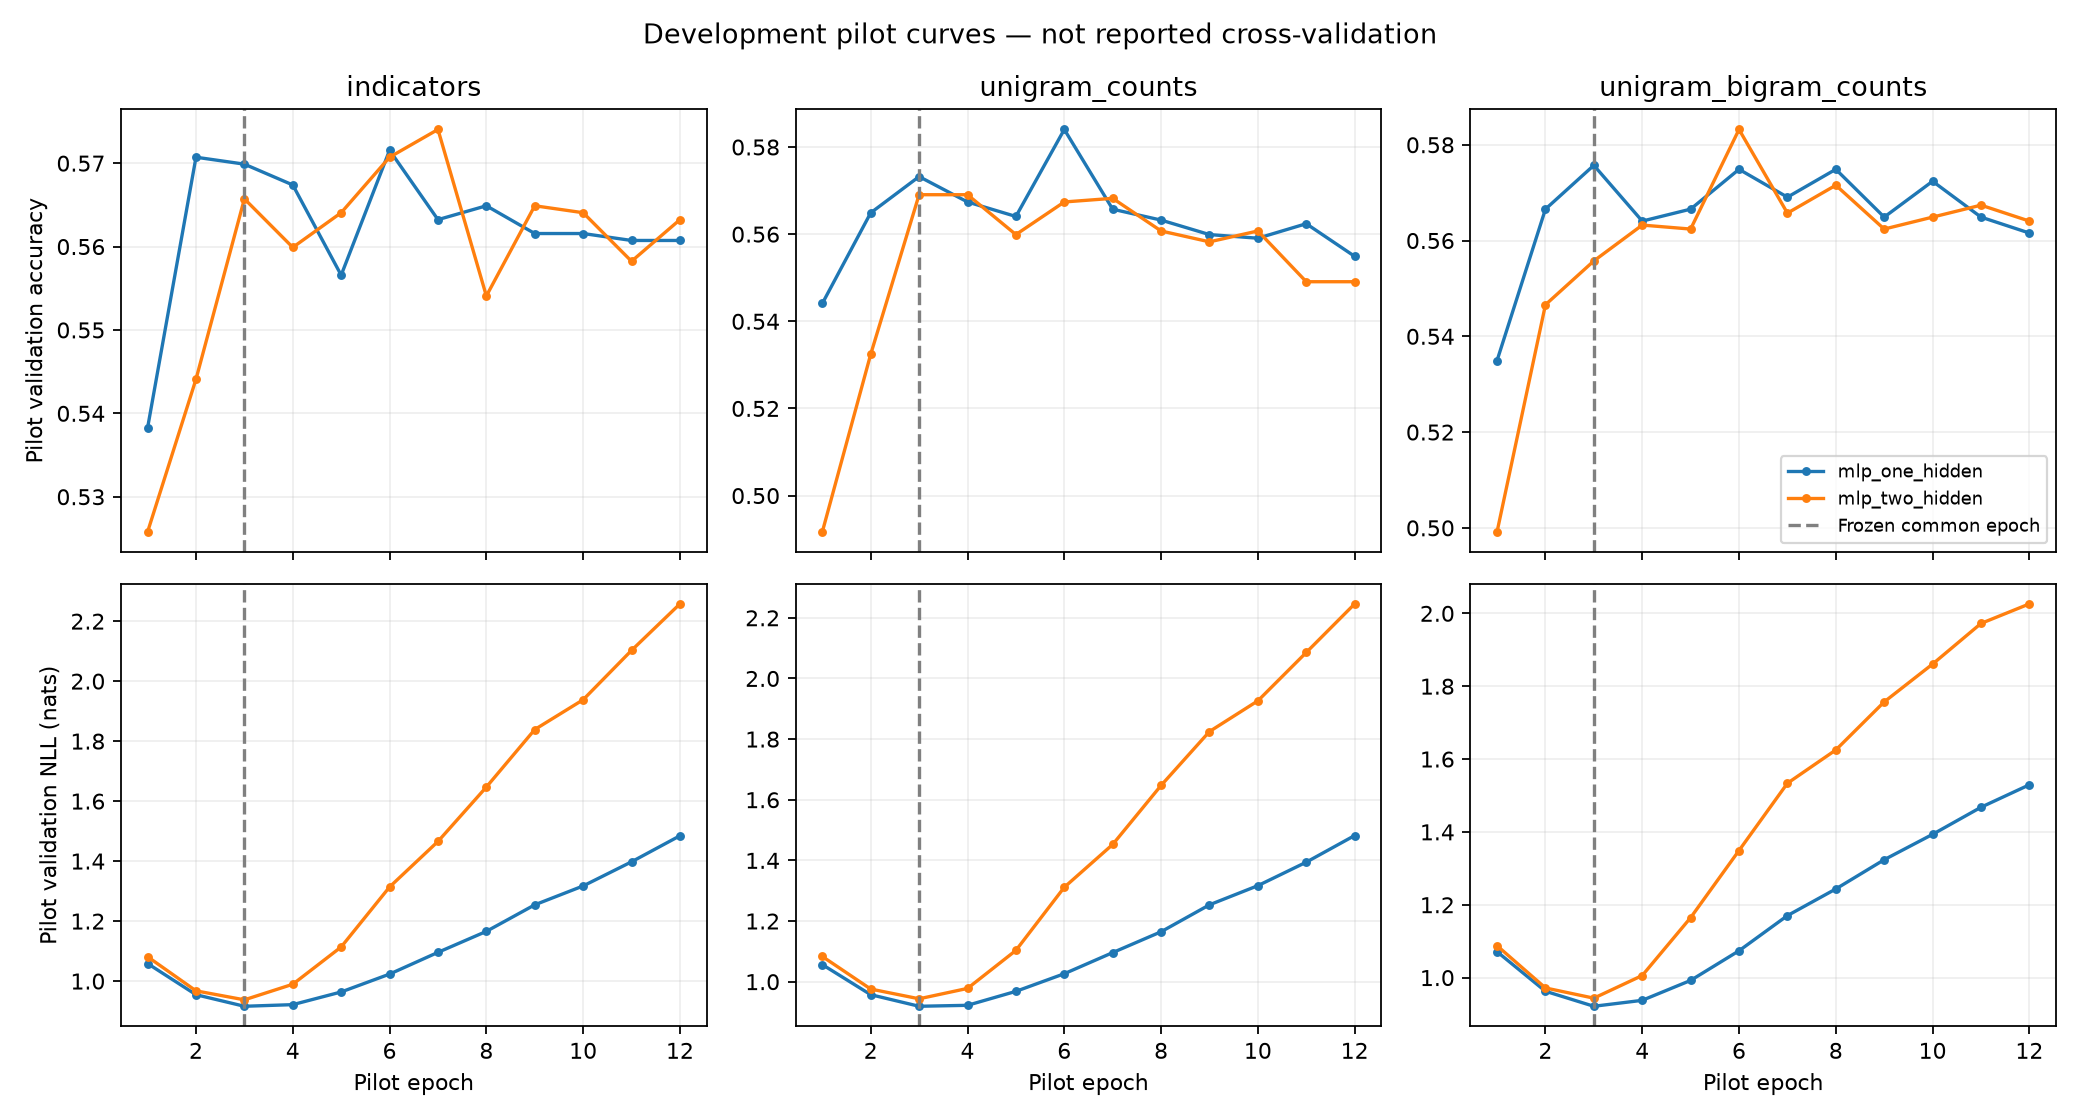

first_online_train_nll  \
representation        classifier                               
indicators            mlp_one_hidden                  1.0975   
                      mlp_two_hidden                  1.0983   
unigram_bigram_counts mlp_one_hidden                  1.1049   
                      mlp_two_hidden                  1.1002   
unigram_counts        mlp_one_hidden                  1.0973   
                      mlp_two_hidden                  1.0985   

                                      last_online_train_nll  \
representation        classifier                              
indicators            mlp_one_hidden                 0.1489   
                      mlp_two_hidden                 0.0450   
unigram_bigram_counts mlp_one_hidden                 0.0630   
                      mlp_two_hidden                 0.0392   
unigram_counts        mlp_one_hidden                 0.1520   
                      mlp_two_hidden                 0.0492   

                                      first_validation_nll  \
representation        classifier                             
indicators            mlp_one_hidden                1.0585   
                      mlp_two_hidden                1.0812   
unigram_bigram_counts mlp_one_hidden                1.0711   
                      mlp_two_hidden                1.0875   
unigram_counts        mlp_one_hidden                1.0563   
                      mlp_two_hidden                1.0832   

                                      last_validation_nll  
representation        classifier                           
indicators            mlp_one_hidden               1.4845  
                      mlp_two_hidden               2.2576  
unigram_bigram_counts mlp_one_hidden               1.5294  
                      mlp_two_hidden               2.0260  
unigram_counts        mlp_one_hidden               1.4820  
                      mlp_two_hidden               2.2460

In [26]:
display(pilot_tables["epoch_selection"].round(6))
display(Image(filename=str(pilot_report["learning_curve_figure"])))
training_curve_summary = pilot_tables["curves"].groupby(["representation", "classifier"]).agg(
    first_online_train_nll=("train_nll_online", "first"),
    last_online_train_nll=("train_nll_online", "last"),
    first_validation_nll=("validation_nll", "first"),
    last_validation_nll=("validation_nll", "last"),
)
display(training_curve_summary.round(4))

### 6.3 Pilot metrics, convergence, predictions, and reloads

The next table evaluates each neural system restored to the selected epoch 3;
its full 12-epoch search is retained separately. The three primary SAGA fits
hit the initial 300-iteration limit; retries with a 1,000-iteration ceiling
converge in 340, 365, and 385 iterations (indicators, counts, extended counts).
The hypothesis-only fit converges in 257 iterations under that ceiling. All
four final fits converge; initial failed attempts remain recorded. Every model
has a saved three-column probability array,
predicted/gold labels, original validation IDs, fixed-order class metrics and
confusion matrix, and a complete prediction bundle.

NLL from probabilities agrees with the log-softmax objective on these data,
and reloading text-pair bundles reproduces the probabilities. Treat comparisons
here as development observations after tuning on this validation sample. For
example, similar hypothesis-only/full-input pilot scores motivate the planned
paired diagnostic; they do not establish a general annotation-artifact result.

In [27]:
pilot_metrics = pilot_tables["metrics"].copy()
pilot_metrics["sampled_process_RSS_MiB"] = pilot_metrics["sampled_peak_process_rss_bytes"] / 2**20
display(pilot_metrics[[
    "representation", "classifier", "input_mode", "accuracy", "nll", "macro_f1",
    "epochs", "converged", "training_seconds", "sampled_process_RSS_MiB",
    "reload_max_abs_difference",
]].round(6))
print("Maximum NLL/objective difference:", pilot_tables["curves"]["nll_objective_abs_difference"].max())
print("All recorded pilot checks passed:", all(pilot_manifest["checks"].values()))

,representation,classifier,input_mode,accuracy,nll,macro_f1,epochs,converged,training_seconds,sampled_process_RSS_MiB,reload_max_abs_difference
0,indicators,logistic,pair,0.553245,1.036159,0.551763,NaN,True,0.839622,962.101562,0.0
1,indicators,mlp_one_hidden,pair,0.569884,0.916044,0.569975,3.0,NaN,1.375126,1054.851562,0.0
2,indicators,mlp_two_hidden,pair,0.565724,0.937532,0.563852,3.0,NaN,1.364769,1060.859375,0.0
3,unigram_counts,logistic,pair,0.559900,1.045533,0.558997,NaN,True,0.789817,1061.113281,0.0
4,unigram_counts,mlp_one_hidden,pair,0.573211,0.918922,0.573239,3.0,NaN,1.311599,1061.148438,0.0
5,unigram_counts,mlp_two_hidden,pair,0.569052,0.943601,0.566401,3.0,NaN,1.312965,1060.664062,0.0
6,unigram_bigram_counts,logistic,pair,0.553245,1.092860,0.551267,NaN,True,1.335854,1060.664062,0.0
7,unigram_bigram_counts,mlp_one_hidden,pair,0.575707,0.921310,0.575065,3.0,NaN,2.537229,1104.609375,0.0
8,unigram_bigram_counts,mlp_two_hidden,pair,0.555740,0.943568,0.554516,3.0,NaN,2.533541,1093.675781,0.0
9,unigram_counts,class_prior,pair,0.350250,1.098567,0.172931,NaN,NaN,0.000025,1084.640625,0.0


Maximum NLL/objective difference: 0.0
All recorded pilot checks passed: True


### 6.4 Runtime/memory evidence and the comparison pool

Cold pilot preprocessing took about 0.98 seconds. At the selected schedule,
measured neural training took about 1.31–2.54 seconds per system; the three
core logistic fits took 0.79–1.34 seconds. Whole-pilot wall time includes all
candidate epochs, evaluation/snapshot IO, baselines, and fold generation.
Memory is sampled **whole-process RSS every 20 ms**, peaking near 1,105 MiB;
it is not an isolated model-allocation measurement. Sparse matrix byte counts
are shown separately below. Host load and sampling affect these measurements.

Project the summed nine-system fit/preprocessing time to 80% training folds,
then multiply by five folds and three repetitions. Use a factor of two as an
explicit planning margin. Consider 15k/30k/60k/full-pool candidates and choose
the largest under a two-hour primary-matrix planning budget. The smaller 15k
candidate is a fallback; the budget is our engineering choice, not a course rule.

The selected target is **60,000 rows**, becoming **60,005 rows in 16,590 complete
premise groups**. Its projection is about 28.8 minutes, or 57.5 minutes with the
margin. Full eligible SNLI projects to about 4.4 hours, or 8.8 with the margin.
These are rough linear projections, not measured CV runtimes; solver scaling,
cache IO, system load, diagnostics, and final refitting can change total cost.

The subset uses the same seed-0 complete-group prefix for every comparison.
It has new saved folds and a separate protocol ID. The reference full-pool folds
remain available; their cached features must not be mixed with subset models.

In [28]:
runtime_projection = pilot_tables["runtime_projection"].copy()
runtime_projection["estimated_minutes"] = runtime_projection["estimated_primary_seconds"] / 60
runtime_projection["minutes_with_margin"] = runtime_projection["conservative_primary_seconds"] / 60
display(runtime_projection[["target_rows", "estimated_minutes", "minutes_with_margin", "within_budget", "selected"]].round(2))

memory_table = pilot_tables["matrix_summary"].copy()
memory_table["csr_MiB"] = memory_table["csr_bytes"] / 2**20
display(memory_table[["partition", "representation", "rows", "columns", "nonzeros", "csr_MiB"]].round(3))
display(pilot_tables["comparison_pool_summary"])
first_fold = pilot_tables["comparison_fold_summary"].iloc[0]
comparison_counts = pd.DataFrame([
    {"label": label, "label_name": name,
     "rows": int(first_fold[f"train_{name}"] + first_fold[f"heldout_{name}"])}
    for label, name in enumerate(LABEL_NAMES)
])
comparison_counts["proportion"] = comparison_counts["rows"] / comparison_counts["rows"].sum()
display(comparison_counts)

,target_rows,estimated_minutes,minutes_with_margin,within_budget,selected
0,15000,7.19,14.38,True,False
1,30000,14.38,28.76,True,False
2,60000,28.76,57.52,True,True
3,549253,263.29,526.59,False,False


,partition,representation,rows,columns,nonzeros,csr_MiB
0,train,indicators,6001,10000,122624,0.958
1,train,unigram_counts,6001,10000,122624,0.958
2,train,unigram_bigram_counts,6001,20000,202995,1.572
3,validation,indicators,1202,10000,28460,0.222
4,validation,unigram_counts,1202,10000,28460,0.222
5,validation,unigram_bigram_counts,1202,20000,41157,0.319


,pool,rows,premise_groups
0,cv_pool,60005,16590
1,pilot_validation,9839,3318
2,final_refit,559164,154028
3,final_test,9824,3323


,label,label_name,rows,proportion
0,0,entailment,20022,0.333672
1,1,neutral,19969,0.332789
2,2,contradiction,20014,0.333539


### 6.5 Frozen recipe and checked comparison folds

[snli_project1_frozen.json](configs/snli_project1_frozen.json) records the actual
selection: 3 neural epochs, one neural CPU thread, SAGA maximum 1,000, unchanged
BPE/bigram and architecture settings, and the 60,000-row group-budget target.
Use this file for Step 7. The original `snli_project1.json` remains the historical
reference/pilot configuration used by sections 1–5.

The new protocol is `3e3b8a39db826f1c`, distinct from the full-pool reference
`0dc6821564b1d3f0`. Its 15 held-out fold sizes range from 11,998 to 12,010 rows;
all partitions contain every class with no shared premise groups. Every row is
held out once per repetition. Budget exclusions, original IDs, group membership,
and exact class counts are saved. Original cleaned reference splits and the
protected test rows are unchanged. This CV pool size must be disclosed when
interpreting future scores; it is not full-data SNLI CV.

The following call verifies/reuses the frozen folds and refreshes the latest
protocol pointer. It performs no model training. **Step 6 outcome:** the pilot,
configuration, data budget, and final assignments are saved before reported
comparisons. **Next: Step 7**, the paired nine-system CV runner and baselines.

In [29]:
frozen_path = Path(pilot_manifest["frozen_configuration"]["path"])
frozen_evaluation = prepare_evaluation_protocol(frozen_path)
assert frozen_evaluation["reused_folds"]
assert len(frozen_evaluation["cv_pool"]) == pilot_manifest["comparison_actual_rows"]
assert all(frozen_evaluation["manifest"]["checks"].values())
print("Frozen configuration:", frozen_path)
print("Fixed neural epochs / threads:", frozen_config["neural_training"]["num_epochs"], frozen_config["neural_training"]["num_threads"])
print("Final CV protocol:", frozen_evaluation["manifest_path"])
print("Actual comparison rows:", len(frozen_evaluation["cv_pool"]))
print("Pilot evidence:", pilot_report["manifest_path"])
display(pilot_tables["comparison_fold_summary"][[
    "seed", "fold", "train_rows", "heldout_rows", "shared_premise_groups",
]])

Frozen configuration: /home/borisv/nlp1-student-gp57/part1/configs/snli_project1_frozen.json
Fixed neural epochs / threads: 3 1
Final CV protocol: /home/borisv/nlp1-student-gp57/part1/results/project1/folds/3e3b8a39db826f1c/protocol.json
Actual comparison rows: 60005
Pilot evidence: /home/borisv/nlp1-student-gp57/part1/results/project1/pilot/c8206b35e66f6918/manifest.json


,seed,fold,train_rows,heldout_rows,shared_premise_groups
0,0,0,48003,12002,0
1,0,1,48003,12002,0
2,0,2,48005,12000,0
3,0,3,48005,12000,0
4,0,4,48004,12001,0
5,3,0,48006,11999,0
6,3,1,48007,11998,0
7,3,2,48007,11998,0
8,3,3,48005,12000,0
9,3,4,47995,12010,0


## 7. Controlled cross-validation comparison

Pending. Run the nine planned combinations on identical saved folds and
record paired scores, probabilities, predictions, runtimes, and model/feature
sizes. Interpret probability-level NLL separately from decision accuracy/F1.

Sources: HC2a PDF pages 46–47 and 51–55; T1 Experiment.

## 8. Bayesian comparison and practical equivalence

Pending. Compare paired fold accuracies using the tutorial's Bayesian
correlated t model, explicitly recording the number of CV repetitions.
Plot posterior differences and report the probabilities on either side of and
inside the motivated ROPE.

Sources: Project 1 checklist; T1 Data analysis model and analysis.py.

## 9. Error analysis and system selection

Pending. Inspect held-out errors, disagreement cases, negation/order effects,
ambiguous labels, and the hypothesis-only diagnostic. Select a design using
performance, posterior uncertainty, simplicity, and computational cost.

Sources: HC2a PDF pages 49–54; How Language Works PDF pages 20–35.

## 10. Refit and final test evaluation

Pending. Freeze the selected pipeline, refit on the documented non-test data,
and evaluate once on the official test split. Save probabilities, accuracy,
NLL, macro-F1, per-class metrics, and a confusion matrix.

## 11. Reproducibility and oral preparation

Pending. Finalize run instructions, findings, citations, and assistance records.
Prepare the compact backup deck/repository URL and practice explaining the
course concepts, alternatives, evidence, and limitations.

Sources: Project 1 checklist; Introduction PDF pages 8–11.

## Sources and assistance

- [Project 1 requirements](project.ipynb) and [tutorial 1](tutorial.ipynb).
- [Lecture-method map and implementation tracker](COURSE_METHODS.md).
- [SNLI dataset](https://huggingface.co/datasets/stanfordnlp/snli) and
  [SNLI paper](https://aclanthology.org/D15-1075/).
- [Findings and decisions](PROJECT1_FINDINGS.md).
- [AI-assistance record](AI_ASSISTANCE.md).

This notebook was initialized with coding-assistant support. The group remains
responsible for reviewing, understanding, and explaining the implementation.